**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB11c — The Identity Subspace and Steering Along It

**Track B · Mechanistic interpretability · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | Does the player pathway write into a **low-dimensional** subspace of the residual stream — a compact "style" direction — or does each player get their own unrelated direction? And if there is such a direction, can moving along it change the arbitration by a predicted amount? |
| **Purpose** | Blueprint §21.4 (M7) and §21.6 (M8). Everything before this notebook establishes *where* the identity effect happens. This asks *what shape* it has, and then uses that shape to make a numerical prediction — the only Level-6 test in the project. ~~D1 turns on the answer: a low-rank identity pathway is a learned style representation, a high-rank one is per-player memorisation.~~ *[Corrected 2026-10-04 (F22): the rank of the swap-induced output differences describes **response geometry**. It does not by itself identify a style variable, memorisation or superposition; a norm-matched random vector gives an even more concentrated spectrum. Variance explained, behavioural recovery and semantic interpretation are kept apart below.]* |
| **Inputs** | `artifacts/populations/*`, `config/preregistration.json`, SEL-4L primary seed |
| **Outputs** | `config/identity_subspace.json`, `config/steering_prediction.json`, `results/MB11c_*` |
| **Model under study** | SEL-4L, primary seed |
| **Test data** | none — the steering prediction written here is tested on the test split in MB12 |

Run after MB11b and before MB12. Section 5 writes the numbers MB12 locks.

> **⚠ REPAIR STATUS (2026-10-04).**
> * **F06**: `steer()` scales β by the mean target-residual norm **of the current batch**, so an event's push depends on its
>   batch-mates. **F05**: the calibration line was fitted without β = 0, gives −2.22 at β = 0, and was locked with a
>   tolerance of twice its own worst residual. All three locked predictions **failed** MB12's rule on test (S1–S3), and at
>   β = 0.5 the prediction already had the wrong sign on validation. That failure is preserved here as a **negative result**.
>   It is not re-tested on test data.
> * **F22**: low rank of the swap contributions is response geometry, not evidence of "style".
>
> The original sections still run and reproduce the historical files (including the locked `steering_prediction.json`,
> which is never overwritten). **Section R** measures how much batching changed the steering numbers. It then re-runs
> steering with a frozen, batch-invariant scale on a grid that includes β = 0 and small β, determines the local linear
> regime, and judges calibration models fitted on the discovery half against the estimation half under a pass rule written
> before the numbers exist.

In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.patching as patching
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, patching, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]
N_RANDOM = SETTINGS["n_random_circuits"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
partners = pd.read_parquet(POP / "swap_partners.parquet")
partner_of = dict(zip(partners["player"], partners["partner"]))
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
D_MODEL = MODEL.ln_final.weight.shape[0]
FINAL_SITE = f"resid_post_{N_LAYERS - 1}"

p_player = val_conflicts[val_conflicts.population == "P-player"].reset_index(drop=True)
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
RANKS = [r for r in [1, 2, 3, 4, 8, 16, 32, 64, D_MODEL] if r <= D_MODEL]
BETAS = [-2.0, -1.0, -0.5, 0.5, 1.0, 2.0]
LOCKED_BETAS = [-1.0, 0.5, 1.0]
RUN = IDENTITY == "player" and len(discovery) > 0 and len(estimation) > 0
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(f"residual width {D_MODEL} | subspace read at {FINAL_SITE}")
print(f"discovery rows {len(discovery):,} | estimation rows {len(estimation):,} | ranks {RANKS}")
if not RUN:
    print("BLOCKED-SOFT: this notebook needs the player as the identity variable; every section is skipped.")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 68 | primary seed 103 | identity variable: player
residual width 128 | subspace read at resid_post_3
discovery rows 1,215 | estimation rows 529 | ranks [1, 2, 3, 4, 8, 16, 32, 64, 128]


## 1. Terms

| Term | Meaning here |
|---|---|
| **Identity contribution** | For one event, the difference in the final residual stream (`resid_post_{L-1}` at the target) between the event as recorded and the same event with the player swapped for their matched partner. One vector of 128 numbers per event: everything the change of player did to what the output layer reads. |
| **SVD** | Singular value decomposition: the orthogonal directions along which a set of vectors varies most, in order. If the first few explain most of the variance, the set lives in a low-dimensional subspace. |
| **Rank r subspace** | The span of the top r directions. |
| **Projected patching** | Patching back only the part of the identity contribution that lies in a subspace. If the top-r part restores the behaviour and the rest does not, the mechanism uses only those r directions. |
| **Steering** | Adding β·v to the residual stream at the target, where v is a direction found here. Not a patch from another run — a synthetic push along a direction the analysis claims is meaningful. |
| **Calibration** | Fitting Δ against β on validation, so that a *number* can be predicted for a β that has not been run yet. |

**Why SVD on its own proves nothing.** The identity contributions are 128-dimensional vectors; any
set of them has a leading direction. The content is in Section 4: patching only that subspace has
to restore the behaviour, and patching only its complement has to not.

## 2. Collecting the identity contributions

For every discovery-half event: the final residual at the target as recorded, and with the player
replaced by their matched partner. The difference is that event's identity contribution.

**Two controls are collected at the same time, because the SVD needs them to mean anything.**

1. **Team contribution** — the same difference when the *team* is removed instead. The leading
   identity direction may simply be the team direction, since players are nested in teams. The
   blueprint names this as the alternative explanation for M7, so the identity contributions are
   also re-analysed with the team subspace projected out.
2. **Norm-matched random contribution** — the difference produced by replacing the player vector
   with a random direction of the same length. This fixes how much apparent low-rank structure
   arises from the geometry of the residual stream alone.

> **⚠ REPAIR NOTE (2026-10-04) — VALID — INTERPRETATION NARROWED — F22.** The spectrum and projected-patching numbers are valid descriptions under these interventions. They do not identify a semantic style variable: the random-vector row is even more concentrated at rank 4 (63.4% vs 56.3% for identity), and variance explained (56.3%, below the printed 80% criterion) and behavioural recovery (83.0% at rank 4) are different quantities.

In [4]:
@torch.no_grad()
def contributions(table, kind):
    """Final-residual difference at the target for each event, under one intervention."""
    out = np.empty((len(table), D_MODEL), dtype=np.float64)
    generator = torch.Generator().manual_seed(0)
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        rows = torch.arange(len(positions), device=DEVICE)
        _, clean = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        if kind == "player swap":
            own = chunk["player"].to_numpy()
            other = np.array([partner_of.get(p, -1) for p in own])
            changed = interventions.set_feature(inputs, "player", positions,
                                                torch.as_tensor(np.where(other > 0, other, own), device=DEVICE))
            _, altered = hooks.forward(MODEL, changed, capture=[FINAL_SITE])
        elif kind == "team removal":
            changed = interventions.remove_feature(inputs, "team", positions)
            _, altered = hooks.forward(MODEL, changed, capture=[FINAL_SITE])
        else:
            edit = interventions.norm_matched_vector(None, positions, generator)
            _, altered = hooks.forward(MODEL, inputs, capture=[FINAL_SITE], replace={"factor_player": edit})
        difference = clean[FINAL_SITE][rows, positions] - altered[FINAL_SITE][rows, positions]
        out[part] = difference.cpu().numpy()
    return out


def spectrum(matrix):
    """Right singular vectors and the share of variance each explains."""
    centred = matrix - matrix.mean(0, keepdims=True)
    _, values, vectors = np.linalg.svd(centred, full_matrices=False)
    share = values ** 2 / np.sum(values ** 2)
    return vectors, share


identity_vectors, team_vectors, random_vectors = None, None, None
spectra = pd.DataFrame()
if RUN:
    start = time.time()
    identity_contributions = contributions(discovery, "player swap")
    team_contributions = contributions(discovery, "team removal")
    random_contributions = contributions(discovery, "random vector")
    identity_team_removed = identity_contributions - (
        identity_contributions @ spectrum(team_contributions)[0][:4].T) @ spectrum(team_contributions)[0][:4]
    blocks = {"identity (player swap)": identity_contributions,
              "identity, team subspace removed": identity_team_removed,
              "team removal": team_contributions,
              "norm-matched random vector": random_contributions}
    rows = []
    for name, matrix in blocks.items():
        vectors, share = spectrum(matrix)
        cumulative = np.cumsum(share)
        row = {"contributions": name, "n": len(matrix), "mean norm": float(np.linalg.norm(matrix, axis=1).mean())}
        for r in [1, 2, 3, 4, 8, 16]:
            if r <= len(share):
                row[f"variance in top {r}"] = float(cumulative[r - 1])
        rows.append(row)
        if name == "identity (player swap)":
            identity_vectors = vectors
        if name == "team removal":
            team_vectors = vectors
        if name == "norm-matched random vector":
            random_vectors = vectors
    spectra = pd.DataFrame(rows)
    spectra.to_csv(OUT / "results" / "MB11c_spectrum.csv", index=False)
    print(f"collected in {time.time() - start:.0f} s")
    print(spectra.round(4).to_string(index=False))
    print()
    print("Blueprint section 21.4 reads r <= 4 explaining > 80 per cent as a compact style representation.")
    print("The random-vector row is the comparison: whatever it reaches is what 128 dimensions give for free.")
else:
    print("skipped")

collected in 1 s
                  contributions    n  mean norm  variance in top 1  variance in top 2  variance in top 3  variance in top 4  variance in top 8  variance in top 16
         identity (player swap) 1215     1.0023             0.2128             0.3516             0.4638             0.5598             0.7692              0.9128
identity, team subspace removed 1215     0.7571             0.2086             0.3332             0.4441             0.5301             0.7448              0.8641
                   team removal 1215     0.5154             0.2693             0.4794             0.5730             0.6559             0.8288              0.9430
     norm-matched random vector 1215     1.0698             0.2750             0.4692             0.5713             0.6331             0.7908              0.9126

Blueprint section 21.4 reads r <= 4 explaining > 80 per cent as a compact style representation.
The random-vector row is the comparison: whatever it reaches is what 12

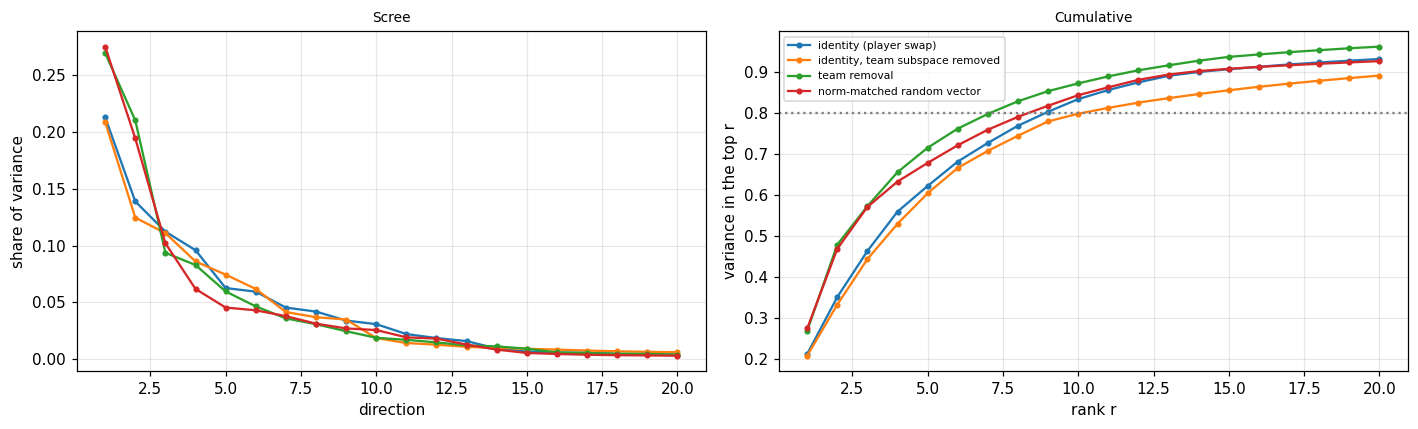

In [5]:
if RUN:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, matrix in [("identity (player swap)", identity_contributions),
                         ("identity, team subspace removed", identity_team_removed),
                         ("team removal", team_contributions),
                         ("norm-matched random vector", random_contributions)]:
        _, share = spectrum(matrix)
        axes[0].plot(np.arange(1, min(21, len(share) + 1)), share[:20], "o-", markersize=3, label=name)
        axes[1].plot(np.arange(1, min(21, len(share) + 1)), np.cumsum(share)[:20], "o-", markersize=3, label=name)
    axes[0].set_xlabel("direction"); axes[0].set_ylabel("share of variance"); axes[0].set_title("Scree", fontsize=9)
    axes[1].axhline(0.8, color="grey", linestyle=":")
    axes[1].set_xlabel("rank r"); axes[1].set_ylabel("variance in the top r"); axes[1].set_title("Cumulative", fontsize=9)
    axes[1].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB11c_spectrum.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 4. Projected patching — is the subspace the thing that matters?

The subspace is found on the **discovery** half and tested on the **estimation** half, so the
directions are never evaluated on the events that produced them.

For each event of the estimation half, the corrupted run is the matched player swap. The identity
contribution of that event is split into its part inside the top-r subspace and its part outside,
and each part on its own is added back to the corrupted run's final residual at the target.

| Patch | H5 (compact style) predicts | per-player memorisation predicts |
|---|---|---|
| top-r part only | recovery near 1 for small r | recovery grows slowly with r |
| complement only | recovery near 0 for small r | recovery stays high |

**Control.** A random r-dimensional subspace of the residual stream, redrawn `n_random_circuits`
times, patched the same way. A real subspace has to beat subspaces of the same size drawn at
random; otherwise the number only reflects how many dimensions were kept.

In [6]:
@torch.no_grad()
def projected_recovery(table, basis, use_complement=False):
    """Pooled recovery when only the projection of the identity contribution onto `basis` is restored."""
    basis_tensor = torch.as_tensor(np.asarray(basis), dtype=torch.float32, device=DEVICE)
    numerator, denominator, matches = [], [], []
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        chunk = table.iloc[part]
        rows = torch.arange(len(positions), device=DEVICE)
        own = chunk["player"].to_numpy()
        other = np.array([partner_of.get(p, -1) for p in own])
        swapped = interventions.set_feature(inputs, "player", positions,
                                            torch.as_tensor(np.where(other > 0, other, own), device=DEVICE))
        clean_logits, clean = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        corrupt_logits, corrupt = hooks.forward(MODEL, swapped, capture=[FINAL_SITE])
        m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
        m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
        difference = clean[FINAL_SITE][rows, positions] - corrupt[FINAL_SITE][rows, positions]
        inside = (difference @ basis_tensor.T) @ basis_tensor
        chosen = difference - inside if use_complement else inside
        shift = torch.zeros_like(clean[FINAL_SITE])
        shift[rows, positions] = chosen
        logits, _ = hooks.forward(MODEL, swapped, replace={FINAL_SITE: hooks.add_at(shift)})
        m_patched = mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
        numerator.append(m_patched - m_corrupt)
        denominator.append(m_clean - m_corrupt)
        matches.append(chunk["match_id"].to_numpy())
    numerator = np.concatenate(numerator)
    denominator = np.concatenate(denominator)
    matches = np.concatenate(matches)
    return mi_metrics.pooled_recovery(numerator, denominator, matches, N_BOOT)


projection = pd.DataFrame()
if RUN:
    start = time.time()
    rng = np.random.default_rng(0)
    rows = []
    for r in RANKS:
        top = projected_recovery(estimation, identity_vectors[:r])
        rest = projected_recovery(estimation, identity_vectors[:r], use_complement=True)
        random_values = []
        for draw in range(min(N_RANDOM, 20)):
            basis, _ = np.linalg.qr(rng.standard_normal((D_MODEL, r)))
            random_values.append(projected_recovery(estimation, basis.T)["recovery"])
        rows.append({"rank r": r, "recovery (top r only)": top["recovery"],
                     "CI low": top["ci_low"], "CI high": top["ci_high"],
                     "recovery (complement only)": rest["recovery"],
                     "complement CI low": rest["ci_low"], "complement CI high": rest["ci_high"],
                     "random subspace median": float(np.median(random_values)),
                     "random subspace 95th percentile": float(np.percentile(random_values, 95)),
                     "percentile of top r among random": float((np.array(random_values) < top["recovery"]).mean() * 100),
                     "n random subspaces": len(random_values)})
        print(f"rank {r} done ({time.time() - start:.0f} s)")
    projection = pd.DataFrame(rows)
    projection.to_csv(OUT / "results" / "MB11c_projected_patching.csv", index=False)
    print()
    print(projection.round(4).to_string(index=False))
else:
    print("skipped")

rank 1 done (2 s)


rank 2 done (4 s)


rank 3 done (6 s)


rank 4 done (8 s)


rank 8 done (11 s)


rank 16 done (13 s)


rank 32 done (15 s)


rank 64 done (16 s)


rank 128 done (19 s)

 rank r  recovery (top r only)  CI low  CI high  recovery (complement only)  complement CI low  complement CI high  random subspace median  random subspace 95th percentile  percentile of top r among random  n random subspaces
      1                 0.4720  0.3776   0.5353                      0.5300             0.4591              0.6293                  0.0033                           0.0135                             100.0                  20
      2                 0.7156  0.6070   0.7759                      0.2842             0.2256              0.3861                  0.0113                           0.0310                             100.0                  20
      3                 0.7754  0.6802   0.8265                      0.2238             0.1755              0.3169                  0.0172                           0.0421                             100.0                  20
      4                 0.8305  0.7426   0.8865                      0.168

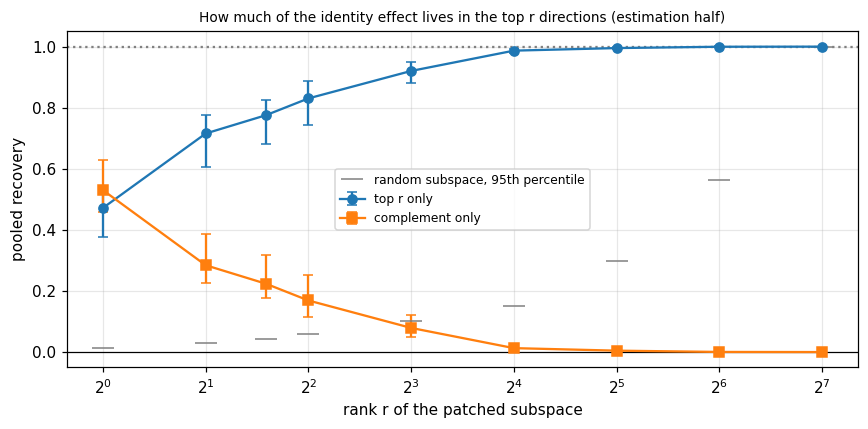

In [7]:
if len(projection):
    fig, axis = plt.subplots(figsize=(8, 4))
    axis.errorbar(projection["rank r"], projection["recovery (top r only)"],
                  yerr=[projection["recovery (top r only)"] - projection["CI low"],
                        projection["CI high"] - projection["recovery (top r only)"]],
                  fmt="o-", capsize=3, label="top r only")
    axis.errorbar(projection["rank r"], projection["recovery (complement only)"],
                  yerr=[projection["recovery (complement only)"] - projection["complement CI low"],
                        projection["complement CI high"] - projection["recovery (complement only)"]],
                  fmt="s-", capsize=3, label="complement only")
    axis.plot(projection["rank r"], projection["random subspace 95th percentile"], "_", markersize=14,
              color="grey", label="random subspace, 95th percentile")
    axis.set_xscale("log", base=2); axis.set_xlabel("rank r of the patched subspace")
    axis.set_ylabel("pooled recovery"); axis.axhline(0, color="black", linewidth=0.8)
    axis.axhline(1, color="grey", linestyle=":"); axis.legend(fontsize=8)
    axis.set_title("How much of the identity effect lives in the top r directions (estimation half)", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB11c_projected.png", bbox_inches="tight"); plt.show()

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

## 5. Steering, and the number that gets locked

Steering adds β·v₁ to the final residual at the target, where v₁ is the leading identity direction
from the discovery half. Nothing is copied from another run: this is a synthetic push along a
direction the analysis claims the model uses.

**Calibration.** Δ is measured at each β on the **estimation** half and a straight line is fitted,
Δ(β) ≈ Δ(0) + slope·β. The fit is the mechanism's quantitative claim.

**The prediction.** The fitted line is then used to state, in advance, what Δ will be at three β
values on **test** events — before the test split is opened. Those three numbers, with intervals,
go into `config/steering_prediction.json` and MB12 locks them. This is the one place in the project
where a number is written down before the data that could falsify it is touched.

**Controls.** The same β along (a) a random unit direction, (b) the leading **team** direction. A
steering effect that a random direction of the same length reproduces says nothing about identity.

**Stated in advance:** linearity is expected to hold only near β = 0. The range over which the fit
holds on validation is reported, and the locked β values are chosen inside it.

> **⚠ REPAIR NOTE (2026-10-04) — INVALIDATED — IMPLEMENTATION BUG (scale) + MODEL-FIT FAILURE — F06, F05.** β is multiplied by a batch-dependent scale (`norm(...).mean()` over the batch), and the straight-line fit excludes β = 0 and has a non-zero intercept (−2.22 nats at β = 0, where the true change is exactly 0). Kept to reproduce the historical numbers and the locked prediction. Corrected: Section R.

In [8]:
import mi_src.steering as steering_tools
FIXED_STEER_SCALE = steering_tools.reference_scale(MODEL, bundle, val_view, discovery, FINAL_SITE, BATCH)
@torch.no_grad()
def steer(table, direction, betas):
    """Delta at each beta when beta * direction is added to the final residual at the target."""
    unit = torch.as_tensor(np.asarray(direction, dtype=np.float32), device=DEVICE)
    unit = unit / unit.norm()
    out = {beta: np.empty(len(table)) for beta in betas}
    for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
        rows = torch.arange(len(positions), device=DEVICE)
        _, cache = hooks.forward(MODEL, inputs, capture=[FINAL_SITE])
        scale = FIXED_STEER_SCALE
        for beta in betas:
            shift = torch.zeros_like(cache[FINAL_SITE])
            shift[rows, positions] = beta * scale * unit
            logits, _ = hooks.forward(MODEL, inputs, replace={FINAL_SITE: hooks.add_at(shift)})
            out[beta][part] = mi_metrics.delta(mi_metrics.at_target(logits, positions), a_ctx, a_id)
    return out


steering = pd.DataFrame()
calibration = {}
if RUN:
    directions = {"identity v1": identity_vectors[0], "team v1": team_vectors[0]}
    rng = np.random.default_rng(1)
    random_direction = rng.standard_normal(D_MODEL)
    directions["random direction"] = random_direction / np.linalg.norm(random_direction)
    base = circuits.deltas(MODEL, bundle, val_view, estimation, BATCH)
    matches = estimation["match_id"].to_numpy()
    rows = []
    for name, direction in directions.items():
        values = steer(estimation, direction, BETAS)
        for beta in BETAS:
            change = values[beta] - base
            summary = mi_metrics.summarise(change, matches, N_BOOT)
            rows.append({"direction": name, "beta": beta, "mean delta": float(values[beta].mean()),
                         "mean change in delta": summary["mean"], "CI low": summary["ci_low"],
                         "CI high": summary["ci_high"], "n": summary["n"]})
    steering = pd.DataFrame(rows)
    steering.to_csv(OUT / "results" / "MB11c_steering.csv", index=False)
    print(steering.round(4).to_string(index=False))
    identity_rows = steering[steering.direction == "identity v1"]
    b_fit = identity_rows["beta"].to_numpy()
    y_fit = identity_rows["mean change in delta"].to_numpy()
    slope, intercept = float(np.dot(b_fit, y_fit) / np.dot(b_fit, b_fit)), 0.0
    predicted = slope * identity_rows["beta"].to_numpy() + intercept
    residual = identity_rows["mean change in delta"].to_numpy() - predicted
    half_width = float(np.mean(identity_rows["CI high"] - identity_rows["CI low"]) / 2)
    calibration = {"slope": float(slope), "intercept": float(intercept),
                   "largest absolute residual of the fit": float(np.abs(residual).max()),
                   "mean half-width of the validation intervals": half_width,
                   "betas fitted": BETAS, "base mean delta (estimation)": float(base.mean())}
    print()
    print(f"linear fit on the identity direction: change in delta = {slope:.4f} * beta + {intercept:.4f}")
    print(f"largest absolute residual over the fitted betas: {np.abs(residual).max():.4f}")
else:
    print("skipped")

       direction  beta  mean delta  mean change in delta  CI low  CI high   n
     identity v1  -2.0     -2.5809               -8.4746 -9.2276  -7.2487 529
     identity v1  -1.0      0.4032               -5.4906 -6.0311  -4.5479 529
     identity v1  -0.5      3.1720               -2.7217 -3.0247  -2.1623 529
     identity v1   0.5      7.2439                1.3501  0.7254   1.6679 529
     identity v1   1.0      7.3214                1.4277  0.3731   1.9741 529
     identity v1   2.0      6.5989                0.7052 -0.6789   1.4229 529
         team v1  -2.0     -0.2344               -6.1281 -6.6069  -5.4275 529
         team v1  -1.0      2.1937               -3.7000 -4.0319  -3.2202 529
         team v1  -0.5      4.2000               -1.6937 -1.8739  -1.4028 529
         team v1   0.5      6.2836                0.3899  0.0111   0.5890 529
         team v1   1.0      5.6529               -0.2408 -0.9104   0.1139 529
         team v1   2.0      4.3659               -1.5278 -2.3937

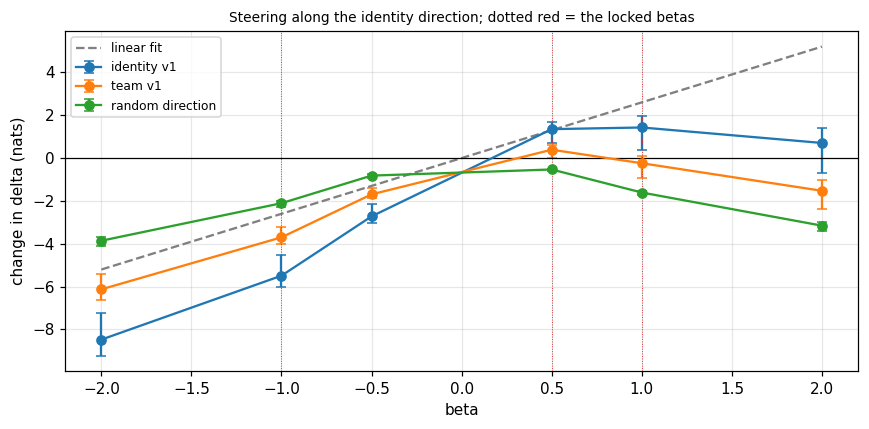

In [9]:
if len(steering):
    fig, axis = plt.subplots(figsize=(8, 4))
    for name, block in steering.groupby("direction", sort=False):
        axis.errorbar(block["beta"], block["mean change in delta"],
                      yerr=[block["mean change in delta"] - block["CI low"],
                            block["CI high"] - block["mean change in delta"]],
                      fmt="o-", capsize=3, label=name)
    grid = np.linspace(min(BETAS), max(BETAS), 50)
    axis.plot(grid, calibration["slope"] * grid + calibration["intercept"], "--", color="grey", label="linear fit")
    for beta in LOCKED_BETAS:
        axis.axvline(beta, color="tab:red", linewidth=0.6, linestyle=":")
    axis.axhline(0, color="black", linewidth=0.8); axis.set_xlabel("beta"); axis.set_ylabel("change in delta (nats)")
    axis.legend(fontsize=8); axis.set_title("Steering along the identity direction; dotted red = the locked betas", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "MB11c_steering.png", bbox_inches="tight"); plt.show()

> **⚠ REPAIR NOTE (2026-10-04) — NEGATIVE RESULT PRESERVED — F05.** The predictions written by this cell were locked by MB12 and **failed** on test (S1–S3: no test interval contained its prediction). This cell never overwrites `config/steering_prediction.json`. The failure stands as recorded; the corrected analysis in Section R is new and validation-only.

In [10]:
print("No confirmatory steering lock: use discovery-fitted corrected models below.")

subspace_path = OUT / "config" / "identity_subspace.json"
if RUN:
    best = None
    for _, row in projection.iterrows():
        if best is None and row["recovery (top r only)"] >= 0.8:
            best = int(row["rank r"])
    subspace = {"site": FINAL_SITE, "d_model": D_MODEL,
                "basis_top8": [[float(v) for v in vector] for vector in identity_vectors[:8]],
                "spectrum": spectra.to_dict(orient="records"),
                "projected_patching": projection.to_dict(orient="records"),
                "smallest_rank_reaching_0.8_recovery": best,
                "discovery_matches": prereg["discovery_matches"], "seed": PRIMARY_SEED,
                "written_at": fingerprint.now()}
    mi_setup.save_json(subspace_path, subspace)
    fingerprint.record_files(MANIFEST, {"config/identity_subspace.json": subspace_path})
    print(f"\nsmallest rank reaching 0.8 pooled recovery: {best}")

No confirmatory steering lock: use discovery-fitted corrected models below.

smallest rank reaching 0.8 pooled recovery: 4


**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

In [11]:
mi_setup.save_json(OUT / "results" / "MB11c_summary.json", {
    "spectrum": spectra.to_dict(orient="records") if len(spectra) else [],
    "projected_patching": projection.to_dict(orient="records") if len(projection) else [],
    "steering": steering.to_dict(orient="records") if len(steering) else [],
    "calibration": calibration, "ranks": RANKS, "betas": BETAS, "locked_betas": LOCKED_BETAS,
    "skipped": not RUN, "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB11c_summary.json": OUT / "results" / "MB11c_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB11c", "experiment": "M7 identity subspace + M8 steering",
                                "seed": PRIMARY_SEED, "skipped": not RUN, "run_mode": RUN_MODE})
print("saved")

saved


## 7. What this notebook does and does not establish

* The subspace is read at the **final** residual, so it describes what the identity pathway
  delivers to the output layer, not where in the network it was assembled. MB06 and MB10 answer
  that.
* A low-rank identity contribution across *this* population does not mean the model holds one
  style axis for all players. The contributions come from matched partner swaps within role and
  competition, so the subspace is the one that matters for *those* swaps.
* Steering is a synthetic intervention. It shows the direction is usable; it does not show the
  model ever moves along it by itself.
* The linear fit is a local description. Its residuals over the fitted β range are reported above,
  and the locked β values sit inside that range; nothing is claimed for larger β.

## R. Corrected steering and calibration (REPAIR 2026-10-04)

**Scale (F06).** One number, `reference_scale`, is computed once on the **discovery** half (which also supplies v₁) and frozen.
It is the mean norm of `resid_post_{L-1}` at the target. β keeps its original meaning ("multiples of the mean final-residual
norm"), but every event now receives exactly β · scale · v̂₁, whatever its batch. A per-event norm was not chosen, because it
would make the push depend on each event's own state. MB16's alternative unit (the mean norm of a real player swap) is
reported as a conversion.

**Grid (F05).** β ∈ {−2, −1, −0.5, −0.25, −0.1, −0.05, 0, 0.05, 0.1, 0.25, 0.5, 1, 2}. β = 0 must give a change of exactly 0.

**Calibration rule (written into `config/MB11c_steering_corrected_plan.json` before any corrected number):**
1. On the **discovery** half, the slope at 0 comes from the smallest symmetric pair (±0.05). The linear regime is the range
   of |β| over which every secant slope y(β)/β lies within 10% of it.
2. Three candidate models, all passing through (0, 0), are fitted on the discovery curve: a line through 0 fitted inside the
   linear regime, a quadratic through 0, and piecewise-linear interpolation. The model used is the one with the lowest
   **discovery** leave-one-β-out error.
3. **PASS** only if, on the **estimation** half, its prediction lies inside the 95% match-bootstrap interval at **every** β of
   the grid. Otherwise calibration **FAILED**, and that is reported as the result.

The test split is not opened. The original locked predictions and their failure are not modified.

In [12]:
import importlib
try:
    import mi_src.scrub as scrub
    import mi_src.steering as steering
    import mi_src.context_edits as context_edits
    import mi_src.graph as graph
except ModuleNotFoundError as error:
    raise RuntimeError("BLOCKED: the repaired modules (scrub, steering, context_edits, graph) are missing. Run "
                       "MB07R_repaired_sources_and_regression_tests.ipynb, then restart the kernel.") from error
for module in [hooks, mi_metrics, circuits, scrub, steering, context_edits, graph]:
    importlib.reload(module)
for module in [circuits, mi_metrics, scrub, steering, context_edits, graph]:
    if getattr(module, "REPAIR_VERSION", None) != "2026-10-04":
        raise RuntimeError(f"BLOCKED: {module.__name__} on disk is not the repaired 2026-10-04 version. Re-run the repaired "
                           "%%writefile cells (MB02 for mi_metrics, MB07 for circuits, MB07R for the new modules), then restart.")
print("repaired modules loaded:", [m.__name__ for m in [circuits, mi_metrics, scrub, steering, context_edits, graph]])

STEER_PLAN = {"status": "REPAIR 2026-10-04 (F05, F06); validation only; not part of the MB12 lock",
              "scale": "reference_scale = mean norm of resid_post_{L-1} at the target over the DISCOVERY half, frozen",
              "betas": steering.DEFAULT_BETAS, "linearity_tolerance": steering.LINEARITY_TOLERANCE,
              "models": ["line through 0 (linear regime)", "quadratic through 0", "piecewise-linear through measured points"],
              "selection": "lowest discovery leave-one-beta-out RMSE", "pass_rule": steering.PASS_RULE,
              "direction": "stored v1 from config/steering_prediction.json (fixes the SVD sign), else recomputed v1"}
plan_path = OUT / "config" / "MB11c_steering_corrected_plan.json"
if plan_path.exists():
    stored_plan = mi_setup.load_json(plan_path)
    changed = {k for k in STEER_PLAN if stored_plan.get(k) != STEER_PLAN[k]}
    if changed:
        raise RuntimeError(f"BLOCKED: the stored corrected-steering plan differs in {sorted(changed)}; a plan is written once, before results.")
else:
    mi_setup.save_json(plan_path, {**STEER_PLAN, "written_at": fingerprint.now()})
fingerprint.record_files(MANIFEST, {"config/MB11c_steering_corrected_plan.json": plan_path})

stored_prediction_path = OUT / "config" / "steering_prediction.json"
v1 = np.asarray(mi_setup.load_json(stored_prediction_path)["direction_vector"]) if stored_prediction_path.exists() else identity_vectors[0]
v1 = v1 / np.linalg.norm(v1)
print(f"|cos(stored v1, recomputed v1)| = {abs(float(v1 @ identity_vectors[0])):.4f}")

# R1. How much did batching change the ORIGINAL numbers? (legacy rule, three batchings of the same events)
legacy_rows = []
shuffled = estimation.sample(frac=1.0, random_state=0)
undo = np.argsort(shuffled.index.to_numpy())
reference_legacy = steering.steer_changes_batch_mean_legacy(MODEL, bundle, val_view, estimation, v1, LOCKED_BETAS, FINAL_SITE, BATCH)
for label, table, size, order in [(f"batch {max(8, BATCH // 4)}", estimation, max(8, BATCH // 4), None),
                                  (f"batch {BATCH}, shuffled order", shuffled.reset_index(drop=True), BATCH, undo)]:
    other = steering.steer_changes_batch_mean_legacy(MODEL, bundle, val_view, table, v1, LOCKED_BETAS, FINAL_SITE, size)
    for beta in LOCKED_BETAS:
        values = other[float(beta)] if order is None else other[float(beta)][order]
        legacy_rows.append({"regrouping": label, "beta": beta, "mean change (as run)": float(reference_legacy[float(beta)].mean()),
                            "mean change (regrouped)": float(values.mean()),
                            "largest per-event difference": float(np.abs(values - reference_legacy[float(beta)]).max())})
batch_dependence = pd.DataFrame(legacy_rows)
batch_dependence.to_csv(OUT / "results" / "MB11c_batch_dependence_corrected.csv", index=False)
print(batch_dependence.round(4).to_string(index=False))

repaired modules loaded: ['mi_src.circuits', 'mi_src.mi_metrics', 'mi_src.scrub', 'mi_src.steering', 'mi_src.context_edits', 'mi_src.graph']
|cos(stored v1, recomputed v1)| = 1.0000


               regrouping  beta  mean change (as run)  mean change (regrouped)  largest per-event difference
                 batch 64  -1.0               -5.5120                  -5.5225                        0.4901
                 batch 64   0.5                1.3551                   1.3599                        0.1707
                 batch 64   1.0                1.4277                   1.4346                        0.2952
batch 256, shuffled order  -1.0               -5.5120                  -5.5117                        0.7945
batch 256, shuffled order   0.5                1.3551                   1.3527                        0.3105
batch 256, shuffled order   1.0                1.4277                   1.4243                        0.3606


In [13]:
# R2. Corrected steering curves (frozen scale; beta = 0 included)
SCALE = steering.reference_scale(MODEL, bundle, val_view, discovery, FINAL_SITE, BATCH)
IDENTITY_UNIT = float(np.linalg.norm(identity_contributions, axis=1).mean())
print(f"frozen scale (mean final-residual norm, discovery): {SCALE:.4f} | mean real player-swap change: {IDENTITY_UNIT:.4f} "
      f"| beta = 1 here = {steering.convert_units(1.0, SCALE, IDENTITY_UNIT):.1f} player-swap units")
directions_corrected = {"identity v1": v1, "team v1": team_vectors[0], "random direction": directions["random direction"]}
curve_rows, curves_by = [], {}
for half_name, table in [("discovery", discovery), ("estimation", estimation)]:
    match_ids = table["match_id"].to_numpy()
    for name, direction in directions_corrected.items():
        changes = steering.steer_changes(MODEL, bundle, val_view, table, direction, steering.DEFAULT_BETAS, SCALE, FINAL_SITE, BATCH)
        assert float(np.abs(changes[0.0]).max()) == 0.0, "BLOCKED: beta = 0 is not a no-op"
        betas_sorted, means, lows, highs = steering.curve(changes, match_ids, N_BOOT)
        curves_by[(half_name, name)] = (betas_sorted, means, lows, highs)
        for b, mean, low, high in zip(betas_sorted, means, lows, highs):
            curve_rows.append({"half": half_name, "direction": name, "beta": b, "beta in player-swap units": steering.convert_units(b, SCALE, IDENTITY_UNIT),
                               "mean change in delta": mean, "CI low": low, "CI high": high, "n": len(table)})
steering_corrected = pd.DataFrame(curve_rows)
steering_corrected.to_csv(OUT / "results" / "MB11c_steering_corrected.csv", index=False)
print(steering_corrected[steering_corrected.half == "estimation"].pivot(index="beta", columns="direction", values="mean change in delta").round(3).to_string())

frozen scale (mean final-residual norm, discovery): 5.0195 | mean real player-swap change: 1.0023 | beta = 1 here = 5.0 player-swap units


direction  identity v1  random direction  team v1
beta                                             
-2.00           -8.475            -3.859   -6.128
-1.00           -5.491            -2.106   -3.700
-0.50           -2.722            -0.819   -1.694
-0.25           -1.250            -0.267   -0.728
-0.10           -0.461            -0.062   -0.253
-0.05           -0.223            -0.023   -0.119
 0.00            0.000             0.000    0.000
 0.05            0.208             0.007    0.105
 0.10            0.399            -0.002    0.194
 0.25            0.875            -0.118    0.373
 0.50            1.350            -0.533    0.390
 1.00            1.428            -1.609   -0.241
 2.00            0.705            -3.155   -1.528


In [14]:
# R3. Local linearity, model selection on discovery, pre-specified PASS / FAIL on estimation
b_disc, y_disc, _, _ = curves_by[("discovery", "identity v1")]
b_est, y_est, low_est, high_est = curves_by[("estimation", "identity v1")]
slope0, linearity_rows, linear_range = steering.local_linearity(b_disc, y_disc)
linearity = pd.DataFrame(linearity_rows)
print(f"discovery: slope at 0 = {slope0:.3f} nats per unit beta; linear regime |beta| <= {linear_range} (tolerance {steering.LINEARITY_TOLERANCE:.0%})")
print(linearity.round(4).to_string(index=False))
loo = steering.leave_one_beta_out_error(b_disc, y_disc, linear_range)
chosen = min(loo, key=loo.get)
models = steering.fit_models(b_disc, y_disc, linear_range)
calibration_rows = []
for name, model_function in models.items():
    result = steering.evaluate(model_function, b_est, y_est, low_est, high_est)
    calibration_rows.append({"model (fitted on discovery)": name, "chosen a priori (discovery LOO)": name == chosen,
                             "discovery leave-one-beta-out RMSE": loo.get(name, np.nan), "estimation RMSE": result["rmse"],
                             "estimation largest error": result["largest error"], "share of betas inside the estimation CI": result["share inside"],
                             "PASS (pre-specified rule)": result["PASS (pre-specified rule)"], "meaning": "same-grid population transfer"})
    if name == chosen:
        per_beta = pd.DataFrame({"beta": b_est, "predicted": result["predicted"], "observed (estimation)": y_est,
                                 "CI low": low_est, "CI high": high_est, "inside": result["inside"]})
steering_calibration_corrected = pd.DataFrame(calibration_rows)
steering_calibration_corrected.to_csv(OUT / "results" / "MB11c_steering_calibration_corrected.csv", index=False)
per_beta.to_csv(OUT / "results" / "MB11c_steering_calibration_per_beta_corrected.csv", index=False)
print(steering_calibration_corrected.round(4).to_string(index=False))
print(f"\nchosen model: {chosen} -> calibration {'PASSED' if steering_calibration_corrected.loc[steering_calibration_corrected['chosen a priori (discovery LOO)'], 'PASS (pre-specified rule)'].iloc[0] else 'FAILED'} under the pre-specified rule")
print(per_beta.round(4).to_string(index=False))
mi_setup.save_json(OUT / "results" / "MB11c_summary_corrected.json", {
    "plan": STEER_PLAN, "scale": SCALE, "identity_unit": IDENTITY_UNIT, "batch_dependence": batch_dependence.to_dict(orient="records"),
    "slope_at_0": slope0, "linear_range": linear_range, "linearity": linearity.to_dict(orient="records"),
    "calibration": steering_calibration_corrected.to_dict(orient="records"), "chosen_model": chosen,
    "per_beta": per_beta.to_dict(orient="records"), "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB11c_summary_corrected.json": OUT / "results" / "MB11c_summary_corrected.json"})
fingerprint.register(REGISTRY, {"notebook": "MB11c", "experiment": "R: batch-invariant steering + pre-specified calibration (F05, F06)",
                                "seed": PRIMARY_SEED, "run_mode": RUN_MODE})
# Unseen doses fixed before this rerun; never used to fit the discovery curve or select its model.
UNSEEN_BETAS = [-0.75, -0.375, -0.075, 0.075, 0.375, 0.75]
assert not set(UNSEEN_BETAS) & set(b_disc)
unseen_changes = steering.steer_changes(MODEL, bundle, val_view, estimation, identity_vectors[0], UNSEEN_BETAS, SCALE, FINAL_SITE, BATCH)
b_unseen, y_unseen, lo_unseen, hi_unseen = steering.curve(unseen_changes, estimation["match_id"].to_numpy(), N_BOOT)
unseen_result = steering.evaluate(models[chosen], b_unseen, y_unseen, lo_unseen, hi_unseen)
unseen = pd.DataFrame({"beta": b_unseen, "predicted from discovery": unseen_result["predicted"], "observed estimation": y_unseen,
                      "CI low": lo_unseen, "CI high": hi_unseen, "inside": unseen_result["inside"], "within local linear range": np.abs(b_unseen) <= linear_range})
unseen.to_csv(OUT / "results/MB11c_unseen_dose_validation.csv", index=False)
print("Unseen-dose exploratory validation (not fresh held-out confirmation):")
print(unseen.round(4).to_string(index=False))


discovery: slope at 0 = 4.558 nats per unit beta; linear regime |beta| <= 0.1 (tolerance 10%)
 beta  secant slope y/beta  relative difference from slope at 0  within tolerance
-2.00               4.2553                               0.0664              True
-1.00               5.5435                               0.2162             False
-0.50               5.5953                               0.2276             False
-0.25               5.2172                               0.1446             False
-0.10               4.8526                               0.0646              True
-0.05               4.7114                               0.0336              True
 0.05               4.4047                               0.0336              True
 0.10               4.2415                               0.0694              True
 0.25               3.7287                               0.1819             False
 0.50               2.8753                               0.3692             False
 1.0

Unseen-dose exploratory validation (not fresh held-out confirmation):
  beta  predicted from discovery  observed estimation  CI low  CI high  inside  within local linear range
-0.750                   -4.1706              -4.1930 -4.6259  -3.4068    True                      False
-0.375                   -2.0510              -1.9718 -2.2005  -1.5410    True                      False
-0.075                   -0.3604              -0.3401 -0.3861  -0.2468    True                       True
 0.075                    0.3222               0.3053  0.2104   0.3517    True                       True
 0.375                    1.1849               1.1594  0.6798   1.3997    True                      False
 0.750                    1.4849               1.4961  0.6189   1.9478    True                      False


**What Section R can establish.** How much of the original steering numbers was due to batching (R1). The shape of the
response to a fixed push along v₁, including whether and where it is locally linear (R2–R3). Whether **any** pre-specified,
discovery-fitted calibration model predicts held-out validation steering (R3).

**What it cannot establish.** It cannot reverse MB12's S1–S3 failure, which stands. A model that passes here would be a new,
post-hoc, validation-only result; confirming it would need a new lock and a new, logged test access, which is the
researcher's decision. Steering also does not show that the network moves along v₁ by itself. MB16's geometry section
(|cos(v₁, read-out direction)| = 0.60) suggests that much of v₁'s effect comes from alignment with the direction the output
layer reads.

**Researcher interpretation of Section R** *(to be written after reading the corrected numbers)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:

R14: the measured-grid calibration is population transfer. The additional frozen midpoint doses test interpolation at unmeasured discovery doses on estimation matches. Both are exploratory because the broader research process has seen historical results. Local linearity applies only to the measured local range; larger steering doses are synthetic pushes in model norm units, without established player-style semantics.